# BIL485 Derin Öğrenme, Ödev 2: Computer Vision
## Food-101 ile yemek fotoğrafı sınıflandırma (sıfırdan CNN ve ResNet-50 transfer learning)

**Problem:** Bir yemek fotoğrafına bakıp onu 101 yemek sınıfından birine atamak (görüntü sınıflandırma).

**Neden bu problem:** Sonuç, Food-101 dışından gerçek yemek fotoğraflarında doğrudan denenebiliyor; Food-101'in 101 sınıfı dengeli ve
birbirine benzeyen yemekler (biftek ve fileto, çikolatalı kek ve çikolatalı mus) modelin nerede zorlandığını görmeyi kolaylaştırıyor.

**Akış**
1. Veri seti ve train / validation / test bölmesi
2. Beklentiler (sonuçları görmeden önce yazıldı)
3. Ortak eğitim düzeni ve hiperparametreler
4. Model 1: sıfırdan eğitilen küçük CNN (temel çizgi)
5. Model 2: ImageNet ile ön-eğitilmiş ResNet-50, ince ayar (transfer learning)
6. Validation'a göre model seçimi, ardından test kümesinde **tek** değerlendirme
7. Hata analizi: sınıf bazında F1, en çok karışan sınıf çiftleri, yanlış örnekler
8. Çıkarım süresi (GPU ve CPU)
9. Food-101 dışından 5 gerçek dünya fotoğrafı + Grad-CAM
10. Uygulama: Gradio web arayüzü
11. Rapor tablosu (`REPORT.md`) ve ham sonuçlar (`results/results.json`)
12. Değerlendirme

**Çalıştırma:** Colab → *Çalışma zamanı → Çalışma zamanı türünü değiştir → GPU* (A100 varsa veri yükleme daha çok CPU
çekirdeğiyle geldiği için belirgin hızlı). Ardından *Tümünü çalıştır*. T4'te toplam süre yaklaşık 1–1,5 saat
(indirme ~10 dk, sıfırdan CNN ~25 dk, ResNet-50 ~30 dk, test ve analiz ~5 dk).

In [1]:
# 0. Kurulum: Colab'de repoyu klonlar ve eksik paketleri kurar
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/uuu4/bil485-cv-food101"

if IN_COLAB and not os.path.exists("food_cv.py"):
    if not os.path.exists("bil485-cv-food101"):
        subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
    os.chdir("bil485-cv-food101")
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gradio", "pillow-heif"], check=True)
print("Çalışma klasörü:", os.getcwd())

Çalışma klasörü: /root/work


In [2]:
import dataclasses, gc, json, shutil, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display

import food_cv as fc
from food_cv import TrainConfig

SEED = 42
QUICK_RUN = os.environ.get("QUICK_RUN", "0") == "1"   # True: akışı birkaç dakikada uçtan uca dener (sınıf başına 20 görüntü, 1 epoch). Rapor için False.
USE_DRIVE = False   # True: checkpoint'ler Google Drive'a yazılır; oturum düşerse eğitim baştan yapılmaz.

PROJECT_TITLE = "Food-101 ile Yemek Fotoğrafı Sınıflandırma: Sıfırdan CNN ve ResNet-50 Transfer Learning"
REPOSITORY = REPO_URL
DATA_ROOT = Path("/content/data") if IN_COLAB else Path("data")
RESULTS = Path("results")
MY_PHOTOS = Path("my_photos")
CKPT_DIR = Path("checkpoints")
VAL_PER_CLASS = 75                      # resmî train'den sınıf başına validation örneği (750 -> 675 train + 75 val)
NUM_WORKERS = min(8, os.cpu_count() or 2)

if USE_DRIVE and IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    CKPT_DIR = Path("/content/drive/MyDrive/bil485-cv-food101/checkpoints")
for d in (RESULTS, CKPT_DIR, MY_PHOTOS):
    d.mkdir(parents=True, exist_ok=True)

fc.seed_everything(SEED)
torch.backends.cudnn.benchmark = True
device = fc.get_device()
env = fc.environment_info()
env["platform"] = "Google Colab" if IN_COLAB else os.environ.get("RUN_PLATFORM", "yerel")
print(json.dumps(env, indent=2, ensure_ascii=False))
if device.type != "cuda":
    print("UYARI: GPU yok. Colab'de Çalışma zamanı → Çalışma zamanı türünü değiştir → GPU seçin.")

{
  "python": "3.12.10",
  "torch": "2.15.0+cu132",
  "cuda_available": true,
  "device": "NVIDIA L4",
  "cpu_count": 21,
  "torchvision": "0.29.2+cu132",
  "cuda": "13.2",
  "platform": "Modal (L4, 8 vCPU)"
}


## 1. Veri seti ve bölme

**Food-101** (Bossard ve ark., ECCV 2014): 101 yemek sınıfı, sınıf başına 1000 görüntü, toplam 101 000.
Resmî bölünme sınıf başına 750 train + 250 test görüntüsü. Görüntülerin uzun kenarı en fazla 512 piksel.

Bilinmesi gereken bir özellik: veri setinin yazarları **train** görüntülerini kasıtlı olarak temizlememiş; içinde aşırı renkli ve
bazen yanlış etiketli örnekler var. **Test** görüntüleri ise elle kontrol edilmiş. Yani model gürültülü etiketlerden öğrenip temiz
etiketlerde ölçülüyor.

**Bölme kuralı**
- *Train:* resmî train kümesinden sınıf başına 675 görüntü (68 175).
- *Validation:* resmî train kümesinden sınıf başına 75 görüntü (7 575), tabakalı ve sabit tohumla seçilir. Epoch seçimi ve iki model
  arasındaki seçim yalnızca buna göre yapılır.
- *Test:* resmî test kümesi (25 250). Hiçbir karar için kullanılmaz; tüm seçimler bittikten sonra bir kez ölçülür.

In [3]:
t0 = time.time()
tr_files, tr_labels, te_files, te_labels, classes = fc.food101_file_lists(DATA_ROOT)
print(f"Food-101 hazır ({(time.time() - t0) / 60:.1f} dk). Sınıf sayısı: {len(classes)}")

train_idx, val_idx = fc.stratified_split(tr_labels, VAL_PER_CLASS, SEED)
test_idx = list(range(len(te_files)))
if QUICK_RUN:
    train_idx = fc.subsample_per_class(train_idx, tr_labels, 20, SEED)
    val_idx = fc.subsample_per_class(val_idx, tr_labels, 5, SEED)
    test_idx = fc.subsample_per_class(test_idx, te_labels, 10, SEED)

assert not set(train_idx) & set(val_idx), "train ve validation çakışıyor"
assert not {tr_files[i] for i in train_idx + val_idx} & {te_files[i] for i in test_idx}, "test sızıntısı"

split = {"train": len(train_idx), "val": len(val_idx), "test": len(test_idx), "val_per_class": VAL_PER_CLASS}
counts = pd.DataFrame({
    "train": pd.Series([tr_labels[i] for i in train_idx]).value_counts(),
    "val": pd.Series([tr_labels[i] for i in val_idx]).value_counts(),
    "test": pd.Series([te_labels[i] for i in test_idx]).value_counts(),
})
print(split)
print("Sınıf başına örnek (min / max):", counts.min().to_dict(), counts.max().to_dict())

Food-101 hazır (1.3 dk). Sınıf sayısı: 101
{'train': 68175, 'val': 7575, 'test': 25250, 'val_per_class': 75}
Sınıf başına örnek (min / max): {'train': 675, 'val': 75, 'test': 250} {'train': 675, 'val': 75, 'test': 250}


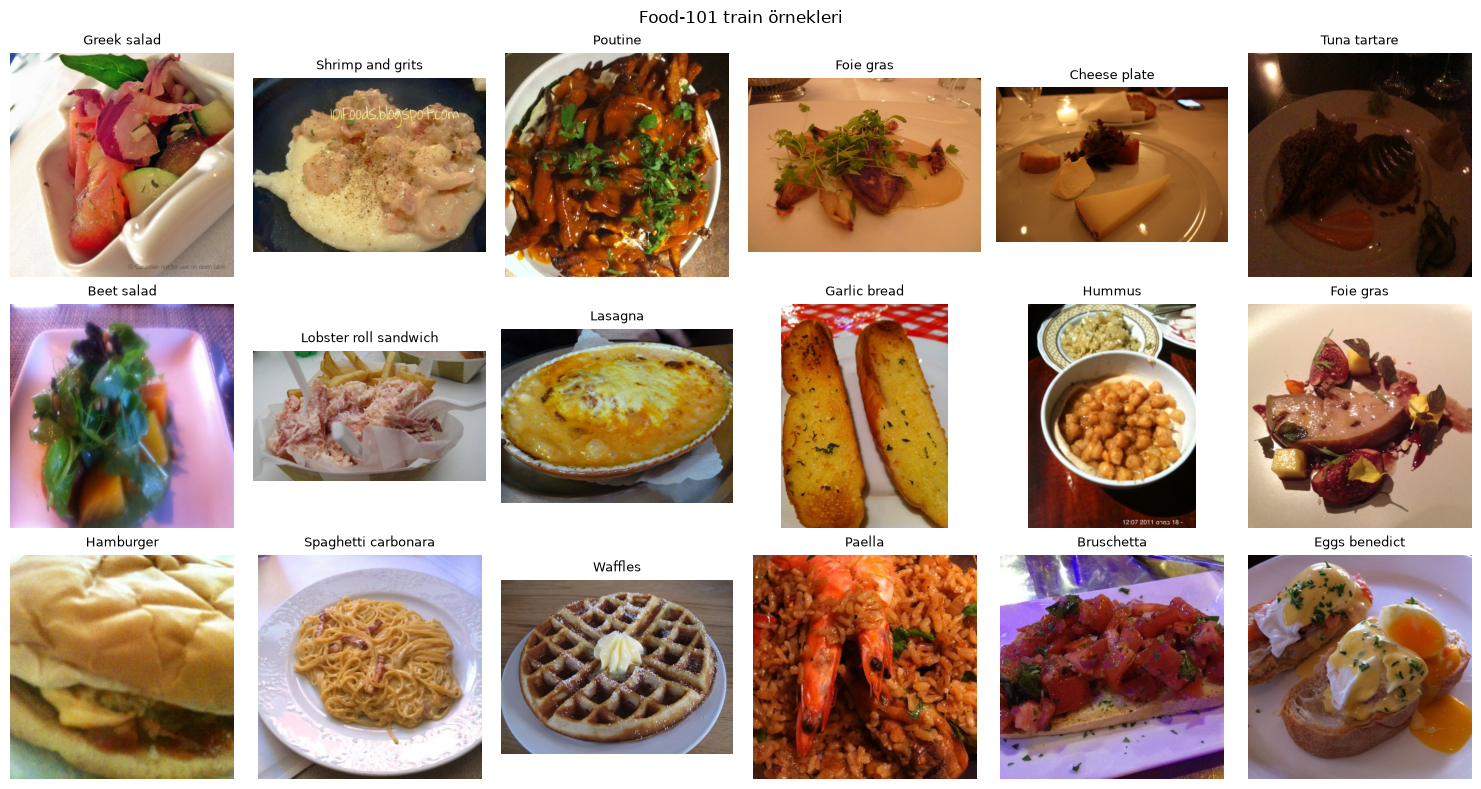

In [4]:
# Train kümesinden rastgele örnekler
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(3, 6, figsize=(15, 8))
for ax, i in zip(axes.flat, rng.choice(train_idx, 18, replace=False)):
    ax.imshow(fc.load_image(tr_files[i]))
    ax.set_title(fc.pretty(classes[tr_labels[i]]), fontsize=9)
    ax.axis("off")
plt.suptitle("Food-101 train örnekleri")
plt.tight_layout()
plt.savefig(RESULTS / "dataset_samples.png", dpi=110, bbox_inches="tight")
plt.show()

## 2. Beklentiler (sonuçları görmeden önce)

1. **Sıfırdan CNN** 6 epoch'ta Food-101'de düşük kalır (%40–55 civarı test doğruluğu). 68 bin görüntü, 101 benzer sınıfı sıfırdan
   ayırt etmeyi öğrenmek için az; kenar, doku ve renk gibi temel özellikleri de bu veriden öğrenmesi gerekiyor.
2. **ResNet-50 transfer learning** aynı sürede çok daha yüksek çıkar (%82–87). ImageNet'ten gelen gövde temel görsel özellikleri
   zaten biliyor; bizim veri yalnız bu özellikleri yemeklere uyarlıyor.
3. En çok karışan sınıflar görünüşü benzeyen yemekler olur: biftek ile fileto, çikolatalı kek ile çikolatalı mus, farklı çorbalar.
4. Gerçek dünya fotoğraflarında Food-101'de olan yemekler büyük ölçüde doğru bilinir. Türk yemekleri gibi **sınıf dışı** yemeklerde model
   yine bir sınıf söylemek zorunda kalır, ama olasılığı düşük olur (ör. lahmacun → pizza).

## 3. Ortak eğitim düzeni

İki model de aynı bölmede, aynı kayıp fonksiyonu ve aynı öğrenme oranı takvimiyle eğitilir:

- **Kayıp:** cross-entropy, label smoothing 0,1 (gürültülü train etiketlerine karşı modelin aşırı emin olmasını azaltır).
- **Optimizer:** AdamW. ResNet-50'de gövde (ön-eğitilmiş katmanlar) sınıflandırıcı başından 10 kat küçük öğrenme oranıyla güncellenir:
  gövde zaten iyi özellikler biliyor, büyük adımlar bunları bozabilir; yeni eklenen son katman ise sıfırdan öğreniyor.
- **Öğrenme oranı takvimi:** ilk yarım epoch doğrusal ısınma, sonra kosinüsle sıfıra iniş.
- **Veri çoğaltma (yalnız train):** rastgele kırpma-ölçekleme (alanın %35–100'ü), yatay çevirme, hafif parlaklık/kontrast/doygunluk.
  Validation ve test: kenarı büyütüp ortadan kare kırpma.
- **Karma hassasiyet (AMP, fp16)** ile GPU'da hızlı eğitim.
- Her epoch sonunda validation ölçülür; **en yüksek validation doğruluğu** veren epoch'un ağırlıkları saklanır.

In [5]:
CFG_CNN = TrainConfig(name="smallcnn", arch="smallcnn", img_size=128, epochs=6, batch_size=128, lr=2e-3,
                      backbone_lr_mult=1.0, weight_decay=5e-4, warmup_epochs=0.5, label_smoothing=0.1,
                      pretrained=False, dropout=0.3)
CFG_RESNET = TrainConfig(name="resnet50", arch="resnet50", img_size=224, epochs=6, batch_size=64, lr=1e-3,
                         backbone_lr_mult=0.1, weight_decay=1e-4, warmup_epochs=0.5, label_smoothing=0.1,
                         pretrained=True, dropout=0.2)
if QUICK_RUN:
    CFG_CNN = dataclasses.replace(CFG_CNN, epochs=1)
    CFG_RESNET = dataclasses.replace(CFG_RESNET, epochs=1)

display(pd.DataFrame([dataclasses.asdict(CFG_CNN), dataclasses.asdict(CFG_RESNET)]).set_index("name").T)

name,smallcnn,resnet50
arch,smallcnn,resnet50
img_size,128,224
epochs,6,6
batch_size,128,64
lr,0.002,0.001
backbone_lr_mult,1.0,0.1
weight_decay,0.0005,0.0001
warmup_epochs,0.5,0.5
label_smoothing,0.1,0.1
optimizer,AdamW,AdamW


In [6]:
def make_split_loaders(img_size, batch_size):
    tr = fc.ImageListDataset([tr_files[i] for i in train_idx], [tr_labels[i] for i in train_idx], fc.train_transform(img_size))
    va = fc.ImageListDataset([tr_files[i] for i in val_idx], [tr_labels[i] for i in val_idx], fc.eval_transform(img_size))
    return (fc.make_loader(tr, batch_size, True, NUM_WORKERS, drop_last=True),
            fc.make_loader(va, 256, False, NUM_WORKERS))


def run_experiment(cfg):
    # Checkpoint varsa (ör. oturum düştü, Drive açık) yeniden eğitmez, kaydedilen geçmişle devam eder.
    ckpt_path = CKPT_DIR / f"{cfg.name}_food101.pt"
    if ckpt_path.exists() and not QUICK_RUN:
        model, meta = fc.load_checkpoint(ckpt_path, device=device)
        if meta["config"] == cfg:
            print(f"{ckpt_path} bulundu, eğitim atlandı.")
            return model, meta["extra"]
        print("Kayıtlı checkpoint farklı ayarlarla eğitilmiş, yeniden eğitiliyor.")
    fc.seed_everything(SEED)
    model = fc.build_model(cfg.arch, len(classes), pretrained=cfg.pretrained, dropout=cfg.dropout)
    train_loader, val_loader = make_split_loaders(cfg.img_size, cfg.batch_size)
    print(f"{cfg.name}: {fc.count_parameters(model) / 1e6:.1f} M parametre, epoch başına {len(train_loader)} adım")
    history, best_epoch, train_time = fc.fit(model, train_loader, val_loader, cfg, device)
    del train_loader, val_loader
    gc.collect()
    extra = {"history": history, "best_epoch": best_epoch, "train_time_s": train_time,
             "best_val_acc": max(h["val_acc"] for h in history)}
    fc.save_checkpoint(model, cfg, classes, ckpt_path, extra=extra)
    return model, extra


def plot_history(history, title, path):
    h = pd.DataFrame(history)
    fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4))
    a.plot(h.epoch, h.train_loss, "o-", label="train (label smoothing'li)")
    a.plot(h.epoch, h.val_loss, "o-", label="validation")
    a.set_title("Kayıp"); a.set_xlabel("epoch"); a.legend()
    b.plot(h.epoch, h.train_acc, "o-", label="train (çoğaltılmış veri)")
    b.plot(h.epoch, h.val_acc, "o-", label="validation")
    b.plot(h.epoch, h.val_top5, "s--", label="validation top-5")
    b.set_title("Doğruluk"); b.set_xlabel("epoch"); b.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(path, dpi=110, bbox_inches="tight")
    plt.show()

## 4. Model 1: sıfırdan eğitilen küçük CNN (temel çizgi)

Dört evrişim bloğu (her blokta iki 3×3 evrişim + Batch Normalization + ReLU, ardından 2×2 max pooling; kanal sayısı 32 → 64 → 128 → 256),
global ortalama havuzlama, dropout ve 101 çıkışlı tam bağlantılı katman. Giriş 128×128 (sıfırdan eğitimde daha hızlı).
Bu model hiçbir ön bilgi olmadan ne kadar ilerlenebildiğini gösteriyor; ResNet-50'nin getirdiği farkı ölçmek için var.

smallcnn: 1.2 M parametre, epoch başına 532 adım


  [smallcnn] epoch 1 adım 100/532 loss 4.535 acc 0.034 (897 görüntü/sn)


  [smallcnn] epoch 1 adım 200/532 loss 4.438 acc 0.046 (1222 görüntü/sn)


  [smallcnn] epoch 1 adım 300/532 loss 4.377 acc 0.054 (1386 görüntü/sn)


  [smallcnn] epoch 1 adım 400/532 loss 4.314 acc 0.064 (1489 görüntü/sn)


  [smallcnn] epoch 1 adım 500/532 loss 4.254 acc 0.074 (1551 görüntü/sn)


... (27 outputs left out)

  [smallcnn] epoch 6 adım 300/532 loss 2.849 acc 0.418 (1841 görüntü/sn)


  [smallcnn] epoch 6 adım 400/532 loss 2.849 acc 0.417 (1837 görüntü/sn)


  [smallcnn] epoch 6 adım 500/532 loss 2.848 acc 0.417 (1848 görüntü/sn)


[smallcnn] epoch 6/6  train loss 2.846 acc 0.417  |  val loss 2.194 acc 0.4808 top5 0.7605  |  0.7 dk
[smallcnn] bitti: en iyi epoch 6 (val acc 0.4808), toplam 4.2 dk


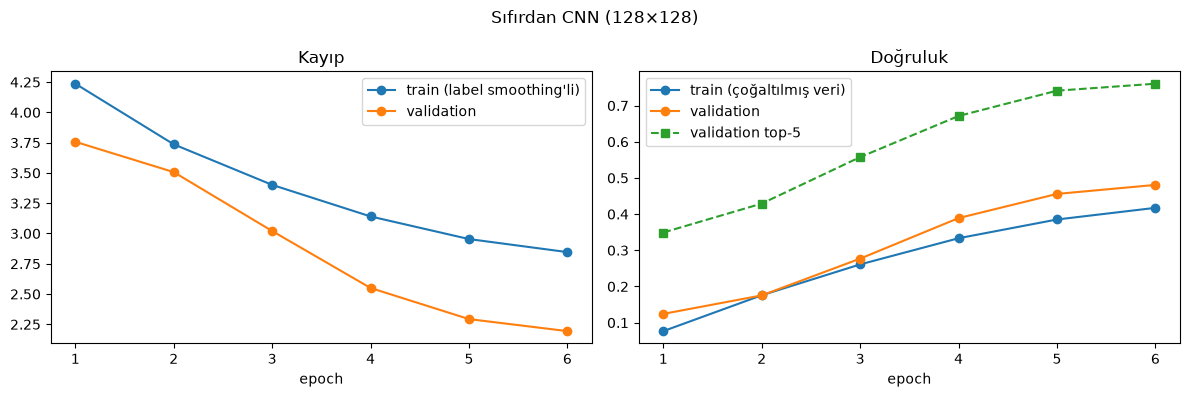

In [7]:
model_cnn, run_cnn = run_experiment(CFG_CNN)
plot_history(run_cnn["history"], "Sıfırdan CNN (128×128)", RESULTS / "curves_smallcnn.png")

## 5. Model 2: ResNet-50, ImageNet ağırlıklarıyla ince ayar (transfer learning)

ResNet-50 (He ve ark., 2016): 50 katmanlı, artık bağlantılı (residual) bir CNN. ImageNet'te (1,28 milyon görüntü, 1000 sınıf) eğitilmiş
ağırlıklarla başlıyoruz (`IMAGENET1K_V2`). Son 1000 sınıflı katman çıkarılıp yerine dropout + 101 sınıflı yeni bir katman konuyor;
ardından **tüm ağ** Food-101'de eğitiliyor (gövde küçük, yeni katman büyük öğrenme oranıyla). Giriş 224×224.

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


  0%|          | 0.00/97.8M [00:00<?, ?B/s]

 13%|█▎        | 13.0M/97.8M [00:00<00:00, 135MB/s]

 27%|██▋       | 26.4M/97.8M [00:00<00:00, 138MB/s]

 41%|████      | 39.8M/97.8M [00:00<00:00, 139MB/s]

 54%|█████▍    | 53.0M/97.8M [00:00<00:00, 139MB/s]

... (67 outputs left out)

  [resnet50] epoch 6 adım 800/1065 loss 1.183 acc 0.901 (500 görüntü/sn)


  [resnet50] epoch 6 adım 900/1065 loss 1.182 acc 0.902 (501 görüntü/sn)


  [resnet50] epoch 6 adım 1000/1065 loss 1.182 acc 0.901 (501 görüntü/sn)


[resnet50] epoch 6/6  train loss 1.183 acc 0.901  |  val loss 0.739 acc 0.8248 top5 0.9534  |  2.4 dk
[resnet50] bitti: en iyi epoch 5 (val acc 0.8260), toplam 14.6 dk


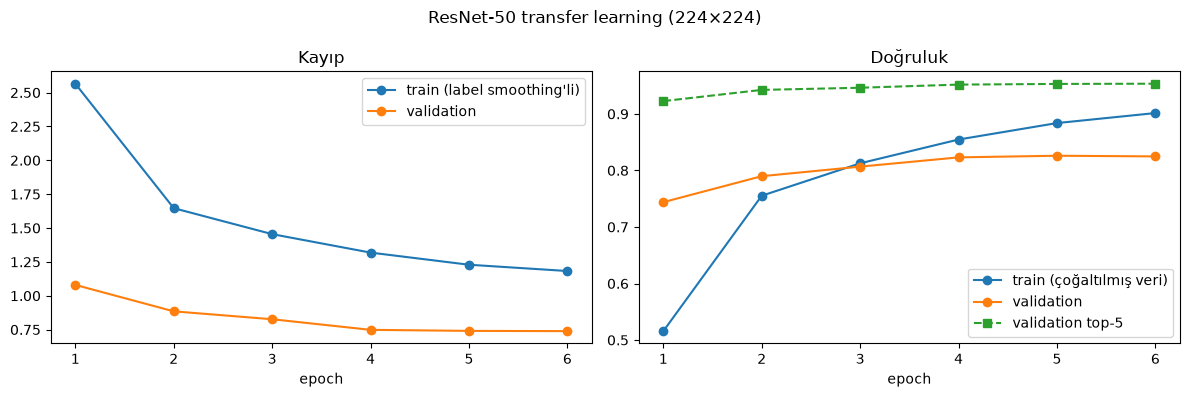

In [8]:
model_res, run_res = run_experiment(CFG_RESNET)
plot_history(run_res["history"], "ResNet-50 transfer learning (224×224)", RESULTS / "curves_resnet50.png")

## 6. Model seçimi (yalnız validation) ve test kümesinde tek değerlendirme

Seçim kuralı: en yüksek validation doğruluğu. Seçim bu hücrede sabitlenir; test sonuçları ondan sonra hesaplanır ve hiçbir ayarı
değiştirmek için kullanılmaz. İki modelin test sonucu da raporlanır (karşılaştırma için), ama seçilen model önceden belli.

In [9]:
runs = {"smallcnn": (CFG_CNN, model_cnn, run_cnn, "Sıfırdan CNN (4 blok)"),
        "resnet50": (CFG_RESNET, model_res, run_res, "ResNet-50 (ImageNet ön-eğitimli, ince ayar)")}
selected = max(runs, key=lambda k: runs[k][2]["best_val_acc"])
print("Validation doğrulukları:", {k: round(v[2]["best_val_acc"], 4) for k, v in runs.items()})
print("Seçilen model:", selected)

test_results, test_outputs = {}, {}
for name, (cfg, model, run, _) in runs.items():
    te_ds = fc.ImageListDataset([te_files[i] for i in test_idx], [te_labels[i] for i in test_idx], fc.eval_transform(cfg.img_size))
    out = fc.evaluate(model, fc.make_loader(te_ds, 256, False, NUM_WORKERS), device, return_outputs=True)
    test_outputs[name] = out
    test_results[name] = fc.classification_metrics(out["logits"], out["labels"], classes)

display(pd.DataFrame({runs[k][3]: {"val acc": runs[k][2]["best_val_acc"], "test acc": m["accuracy"], "test top-5": m["top5_accuracy"],
                                   "macro precision": m["macro_precision"], "macro recall": m["macro_recall"],
                                   "macro F1": m["macro_f1"], "eğitim süresi (dk)": runs[k][2]["train_time_s"] / 60}
                      for k, m in test_results.items()}).round(4))

Validation doğrulukları: {'smallcnn': 0.4808, 'resnet50': 0.826}
Seçilen model: resnet50


,Sıfırdan CNN (4 blok),"ResNet-50 (ImageNet ön-eğitimli, ince ayar)"
val acc,0.4808,0.8260
test acc,0.5225,0.8699
test top-5,0.8030,0.9737
macro precision,0.5096,0.8702
macro recall,0.5225,0.8699
macro F1,0.5091,0.8693
eğitim süresi (dk),4.2079,14.5948


## 7. Hata analizi (seçilen model)

In [10]:
m = test_results[selected]
pc = pd.DataFrame(m["per_class"]).sort_values("f1")
pc["class"] = pc["class"].map(fc.pretty)
print("En zor 10 sınıf (F1'e göre):")
display(pc.head(10).round(3).reset_index(drop=True))
print("En kolay 10 sınıf:")
display(pc.tail(10).iloc[::-1].round(3).reset_index(drop=True))
print("En çok karışan sınıf çiftleri (gerçek → tahmin):")
display(pd.DataFrame(m["top_confused_pairs"]).assign(true=lambda d: d.true.map(fc.pretty), pred=lambda d: d.pred.map(fc.pretty),
                                                       rate=lambda d: d.rate.round(3)))

En zor 10 sınıf (F1'e göre):


,class,precision,recall,f1,support
0,Steak,0.585,0.592,0.588,250
1,Pork chop,0.683,0.604,0.641,250
2,Chocolate mousse,0.679,0.736,0.706,250
3,Apple pie,0.832,0.632,0.718,250
4,Filet mignon,0.697,0.756,0.726,250
5,Bread pudding,0.777,0.712,0.743,250
6,Foie gras,0.847,0.664,0.744,250
7,Tuna tartare,0.773,0.748,0.760,250
8,Ravioli,0.787,0.740,0.763,250
9,Huevos rancheros,0.772,0.772,0.772,250


En kolay 10 sınıf:


,class,precision,recall,f1,support
0,Edamame,0.992,0.992,0.992,250
1,Macarons,0.988,0.972,0.980,250
2,Deviled eggs,0.946,0.972,0.959,250
3,Oysters,0.953,0.964,0.958,250
4,Seaweed salad,0.967,0.936,0.951,250
5,Sashimi,0.941,0.960,0.950,250
6,Miso soup,0.955,0.940,0.948,250
7,Hot and sour soup,0.931,0.964,0.947,250
8,Cannoli,0.931,0.964,0.947,250
9,Bibimbap,0.937,0.952,0.944,250


En çok karışan sınıf çiftleri (gerçek → tahmin):


,true,pred,count,rate
0,Steak,Filet mignon,40,0.160
1,Chocolate cake,Chocolate mousse,25,0.100
2,Filet mignon,Steak,25,0.100
3,Prime rib,Steak,23,0.092
4,Tuna tartare,Beef tartare,23,0.092
5,Chocolate mousse,Chocolate cake,20,0.080
6,Pork chop,Filet mignon,19,0.076
7,Pork chop,Grilled salmon,19,0.076
8,Steak,Prime rib,18,0.072
9,Pork chop,Steak,18,0.072


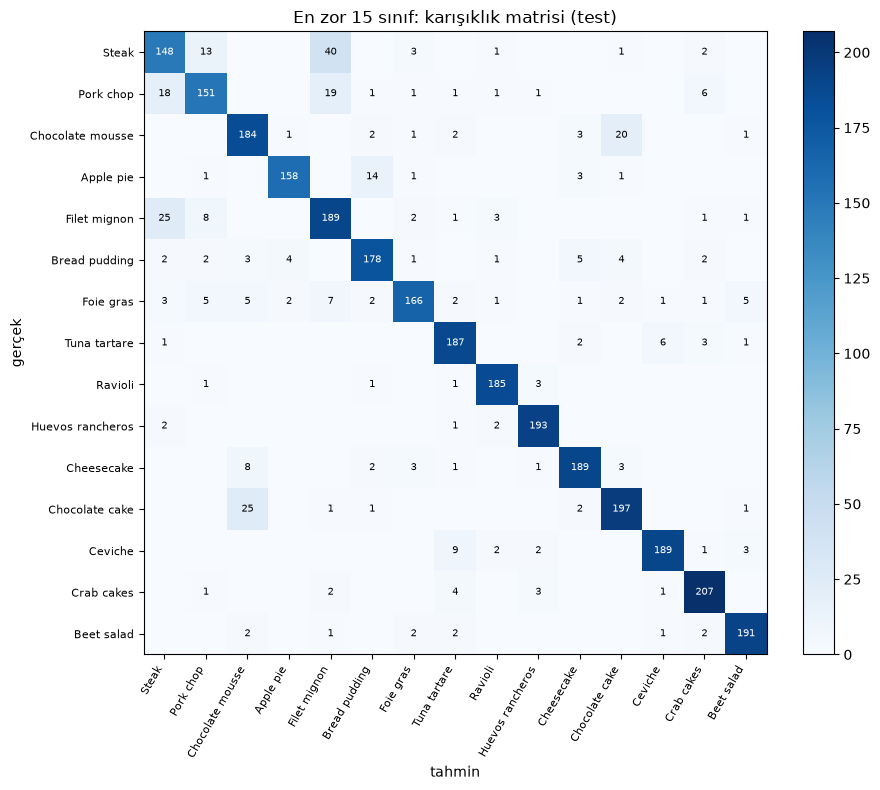

In [11]:
# En zor 15 sınıf arasındaki karışıklık matrisi (101×101 okunmuyor)
worst = [classes.index(c) for c in pd.DataFrame(m["per_class"]).sort_values("f1")["class"].head(15)]
cm = np.asarray(m["confusion_matrix"])
sub = cm[np.ix_(worst, worst)]
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(sub, cmap="Blues")
ax.set_xticks(range(len(worst)), [fc.pretty(classes[i]) for i in worst], rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(worst)), [fc.pretty(classes[i]) for i in worst], fontsize=8)
for i in range(len(worst)):
    for j in range(len(worst)):
        if sub[i, j]:
            ax.text(j, i, sub[i, j], ha="center", va="center", fontsize=7, color="white" if sub[i, j] > sub.max() / 2 else "black")
ax.set_xlabel("tahmin"); ax.set_ylabel("gerçek")
ax.set_title("En zor 15 sınıf: karışıklık matrisi (test)")
plt.colorbar(im, fraction=0.046)
plt.tight_layout()
plt.savefig(RESULTS / "confusion_worst15.png", dpi=110, bbox_inches="tight")
plt.show()

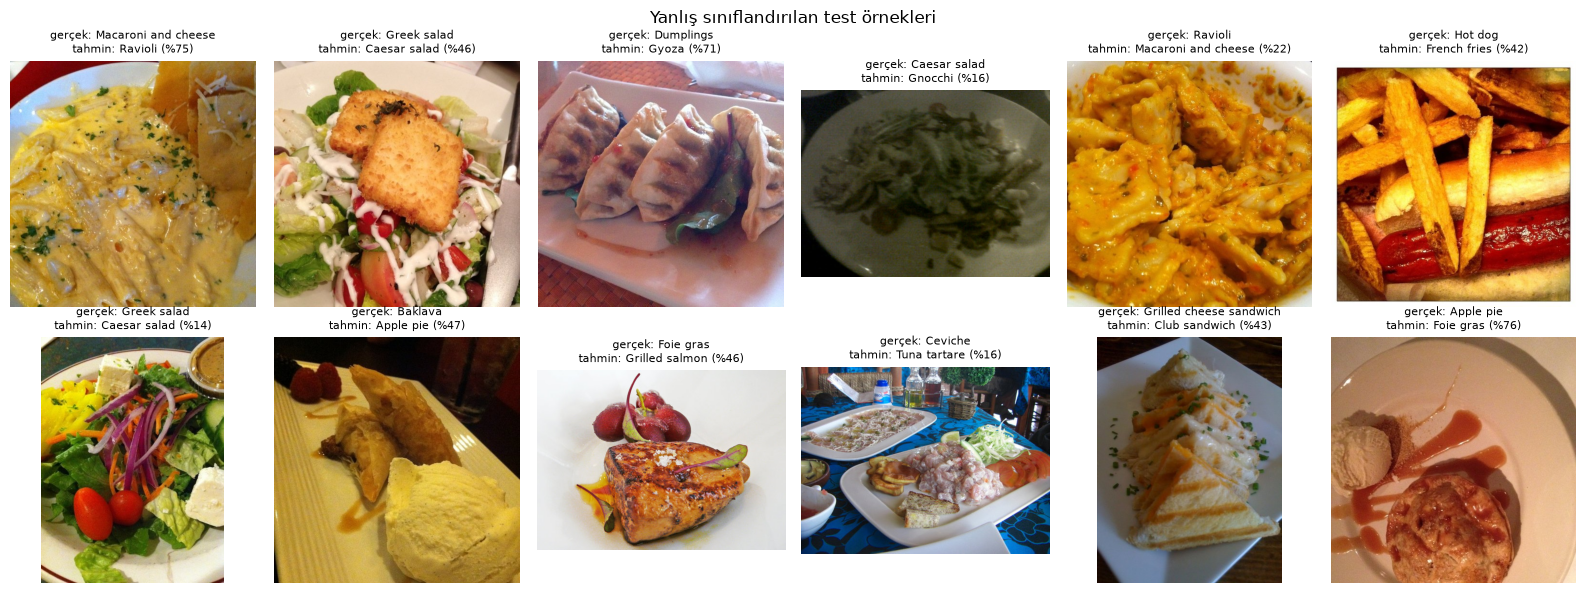

In [12]:
# Yanlış sınıflandırılmış test örnekleri
out = test_outputs[selected]
probs = torch.tensor(out["logits"]).softmax(1).numpy()
wrong = np.flatnonzero(out["logits"].argmax(1) != out["labels"])
pick = np.random.default_rng(SEED).choice(wrong, min(12, len(wrong)), replace=False)
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for ax, k in zip(axes.flat, pick):
    p = probs[k].argmax()
    ax.imshow(fc.load_image(te_files[test_idx[k]]))
    ax.set_title(f"gerçek: {fc.pretty(classes[out['labels'][k]])}\ntahmin: {fc.pretty(classes[p])} (%{100 * probs[k, p]:.0f})", fontsize=8)
    ax.axis("off")
plt.suptitle("Yanlış sınıflandırılan test örnekleri")
plt.tight_layout()
plt.savefig(RESULTS / "test_errors.png", dpi=110, bbox_inches="tight")
plt.show()

## 8. Çıkarım süresi

Tek görüntü (batch 1) için modelin ileri geçiş süresi, ısınmadan sonra 50 ölçümün medyanı. Ön işleme (okuma, yeniden boyutlandırma)
dahil değil. CPU ölçümü, uygulamanın GPU'suz bir sunucuda çalışacağı durumu gösterir.

In [13]:
inference = {}
for name, (cfg, model, run, _) in runs.items():
    gpu_ms = fc.time_inference(model, device, cfg.img_size) if device.type == "cuda" else None
    cpu_model = fc.build_model(cfg.arch, len(classes), pretrained=False, dropout=cfg.dropout)
    cpu_model.load_state_dict({k: v.cpu() for k, v in model.state_dict().items()})
    cpu_ms = fc.time_inference(cpu_model, torch.device("cpu"), cfg.img_size, n_warmup=3, n_runs=20)
    inference[name] = {"gpu_ms": gpu_ms, "cpu_ms": cpu_ms, "gpu": env["device"] if gpu_ms else None}
    del cpu_model
display(pd.DataFrame(inference).T)

,gpu_ms,cpu_ms,gpu
smallcnn,1.414468,26.028026,NVIDIA L4
resnet50,7.694813,117.648692,NVIDIA L4


## 9. Food-101 dışından gerçek dünya fotoğrafları

Bu sürümde `my_photos/` klasöründeki 5 fotoğraf **telefonla çekilmedi, Wikimedia Commons'tan alındı** (açık lisanslı; yazar ve lisanslar `my_photos/SOURCES.md`'de). Hiçbiri Food-101'den değil. Kendi telefon fotoğraflarınızla değiştirmek için dosyaları aynı kurala göre koymanız yeterli. **Dosya adı gerçek etiketi söyler:** Food-101 sınıf adı
(ör. `pizza.jpg`, `french_fries.jpg`, `ice_cream-2.heic`), sınıf dışı bir yemekse kendi adı (ör. `lahmacun.jpg`). Aynı sınıftan ikinci
fotoğraf için `-2` eklenir. Telefonun yan kaydettiği fotoğrafların yönü EXIF bilgisinden düzeltilir; iPhone HEIC dosyaları da okunur.

Her fotoğraf için: modelin gördüğü kare, Grad-CAM ısı haritası ve ilk 5 tahmin.

,dosya,gerçek,Food-101'de,tahmin,olasılık,doğru (top-1),doğru (top-5),gerçek sınıfın sırası
0,baklava.jpg,Baklava,True,Baklava,0.931,True,True,1.0
1,fried_calamari.jpg,Fried calamari,True,Onion rings,0.767,False,True,2.0
2,hamburger.jpg,Hamburger,True,Hamburger,0.564,True,True,1.0
3,lahmacun.jpg,Lahmacun,False,Pizza,0.632,False,False,NaN
4,pizza.jpg,Pizza,True,Pizza,0.493,True,True,1.0


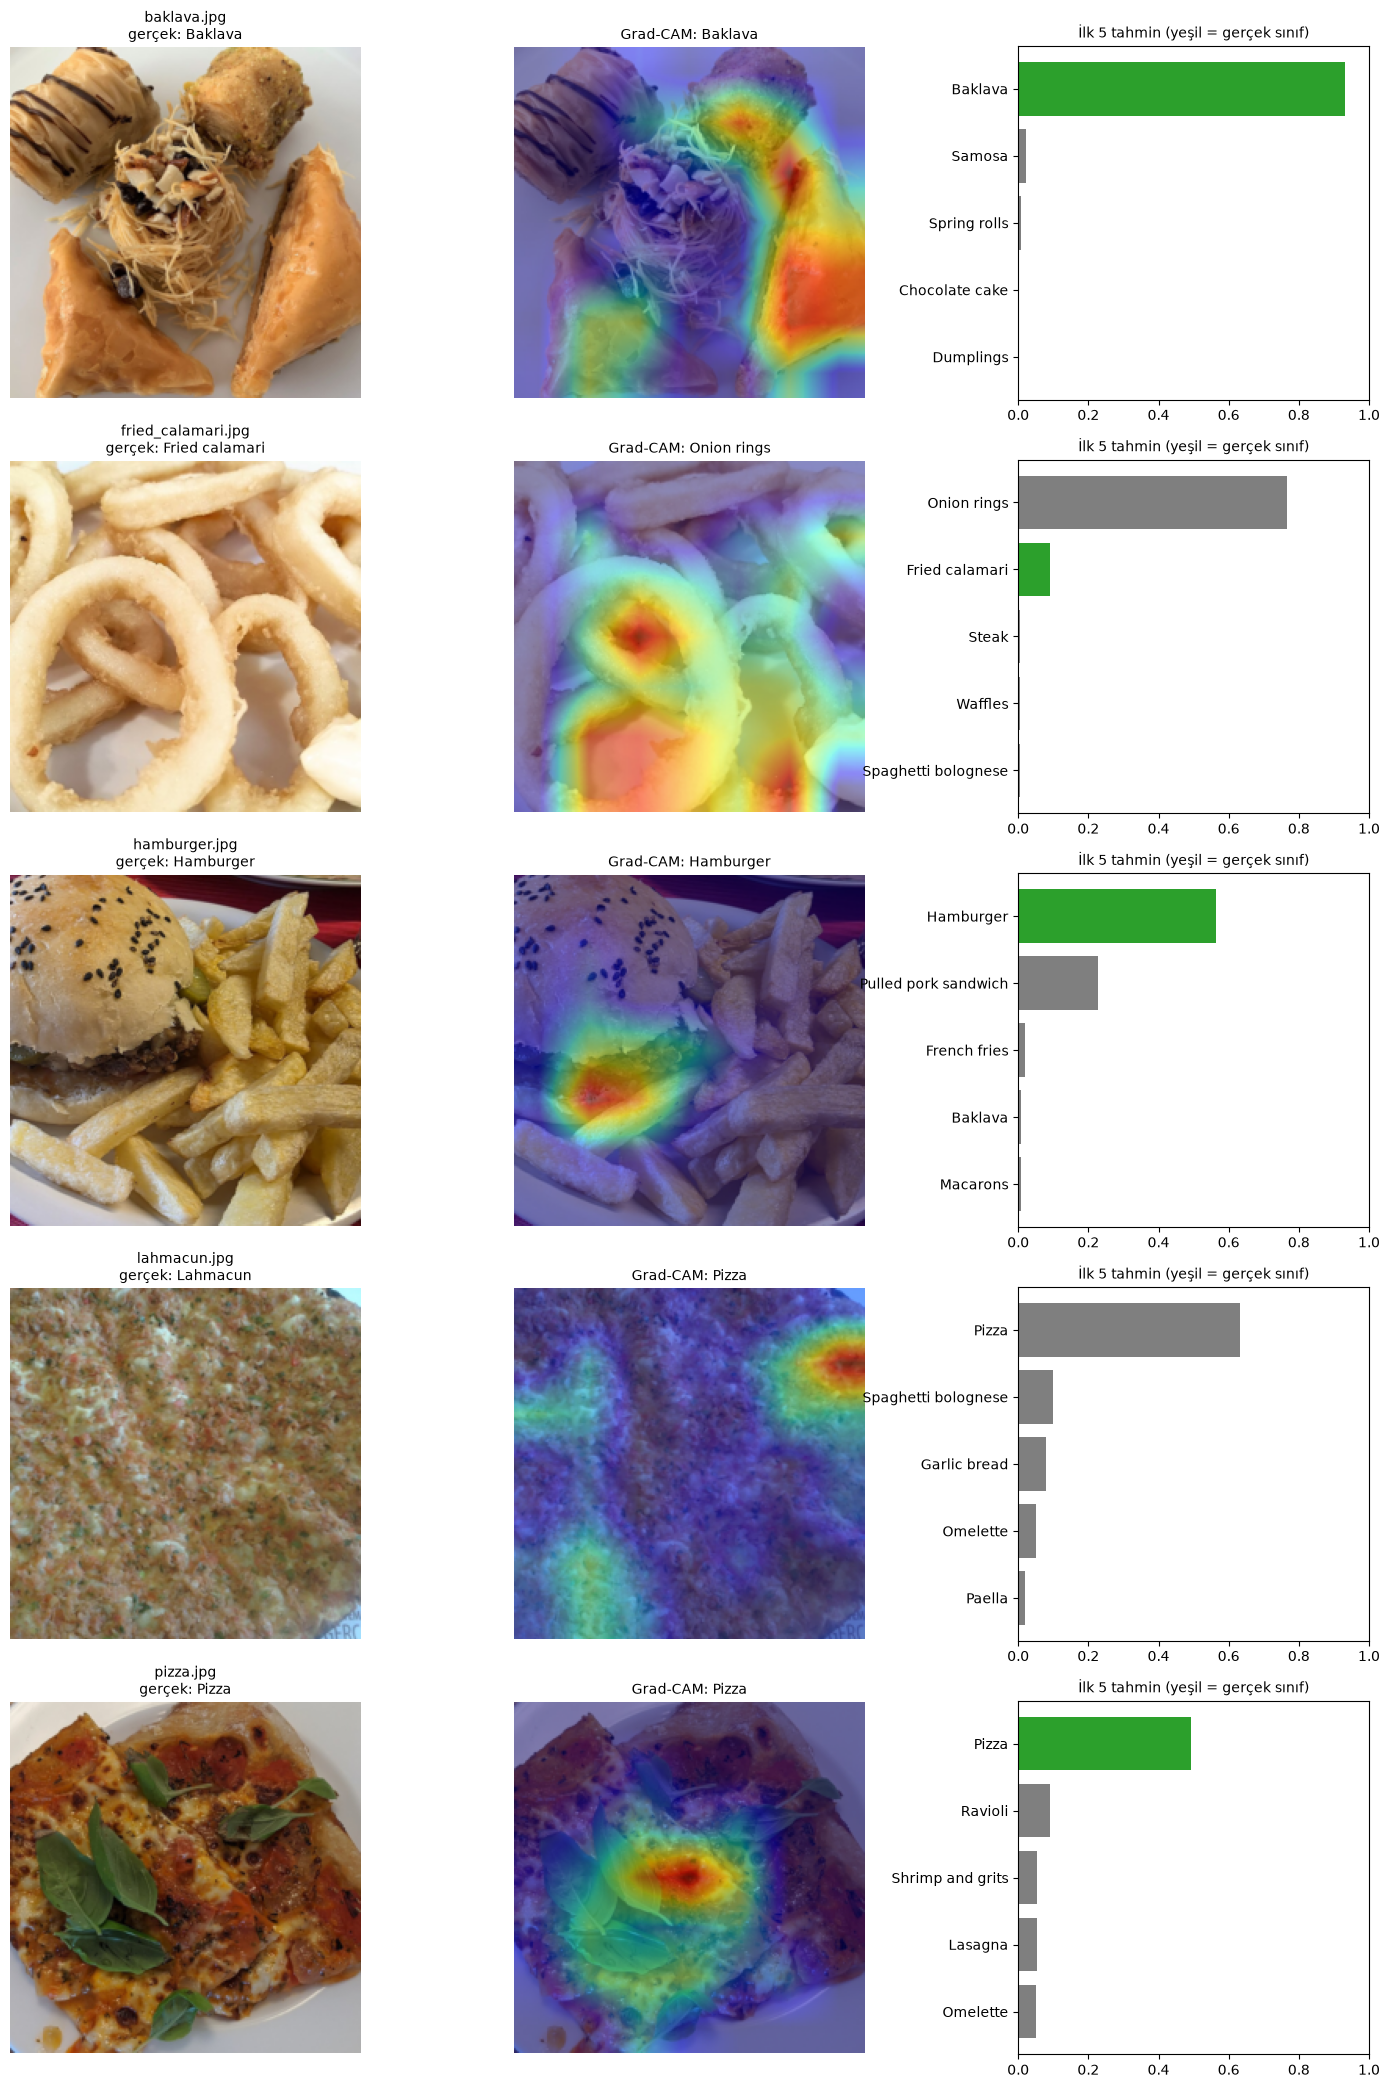

In [14]:
if IN_COLAB and not fc.list_images(MY_PHOTOS):
    from google.colab import files
    print("my_photos/ boş: fotoğrafları seçin (dosya adı = gerçek etiket).")
    for fname, data in files.upload().items():
        (MY_PHOTOS / fname).write_bytes(data)
converted = fc.convert_heic_to_jpeg(MY_PHOTOS)
if converted:
    print("HEIC -> JPEG:", [p.name for p in converted])

model_sel, cfg_sel = runs[selected][1], runs[selected][0]
my_rows = fc.evaluate_my_photos(model_sel, MY_PHOTOS, classes, cfg_sel.img_size, device)
if not my_rows:
    print("my_photos/ içinde fotoğraf yok; bu bölüm atlandı.")
else:
    display(pd.DataFrame([{"dosya": r["file"], "gerçek": fc.pretty(r["true_label"]), "Food-101'de": r["in_food101"],
                           "tahmin": fc.pretty(r["pred_top1"]), "olasılık": round(r["pred_top1_prob"], 3),
                           "doğru (top-1)": r["correct_top1"], "doğru (top-5)": r["correct_top5"],
                           "gerçek sınıfın sırası": r["true_rank"]} for r in my_rows]))
    fig, axes = plt.subplots(len(my_rows), 3, figsize=(14, 4.2 * len(my_rows)), squeeze=False)
    for (a0, a1, a2), r in zip(axes, my_rows):
        img = fc.load_image(MY_PHOTOS / r["file"])
        cam, view, _ = fc.grad_cam(model_sel, img, cfg_sel.img_size, device, class_idx=classes.index(r["pred_top1"]))
        a0.imshow(view); a0.set_title(f"{r['file']}\ngerçek: {fc.pretty(r['true_label'])}", fontsize=10); a0.axis("off")
        a1.imshow(fc.overlay_cam(view, cam)); a1.set_title(f"Grad-CAM: {fc.pretty(r['pred_top1'])}", fontsize=10); a1.axis("off")
        names = [fc.pretty(c) for c, _ in r["top5"]][::-1]
        vals = [p for _, p in r["top5"]][::-1]
        colors = ["tab:green" if c == r["true_label"] else "tab:gray" for c, _ in r["top5"]][::-1]
        a2.barh(names, vals, color=colors); a2.set_xlim(0, 1); a2.set_title("İlk 5 tahmin (yeşil = gerçek sınıf)", fontsize=10)
    plt.tight_layout()
    plt.savefig(RESULTS / "my_photos_predictions.png", dpi=110, bbox_inches="tight")
    plt.show()

## 10. Uygulama: Gradio web arayüzü

`app.py`, kaydedilen checkpoint'i yükleyip bir web arayüzü açar: kullanıcı fotoğraf yükler (ya da kamerayla çeker), model ilk 5 tahmini
olasılıklarıyla ve **Grad-CAM** ısı haritasıyla (modelin karar verirken en çok baktığı bölge) gösterir. En olası sınıfın olasılığı %40'ın
altındaysa "fotoğraf 101 sınıftan birine ait olmayabilir" uyarısı verir. §9'daki fotoğraflar arayüzde örnek olarak hazır gelir.

Aşağıdaki hücre `share=True` ile geçici herkese açık bir bağlantı üretir (Colab'de 72 saat geçerli). Bilgisayarda çalıştırmak için:
`python app.py` (checkpoint `checkpoints/` altında olmalı).

In [15]:
from app import create_demo

demo = create_demo(CKPT_DIR / f"{selected}_food101.pt", device=device, examples_dir=MY_PHOTOS)

# Arayüzün tahmin fonksiyonunu örnek fotoğraflarla sına (arayüze yüklenen fotoğrafla aynı yol)
for p in fc.list_images(MY_PHOTOS):
    _, _, msg = demo.fn(str(p))
    print(f"{p.name}: {msg.splitlines()[0]}")

if IN_COLAB:
    demo.launch(share=True)   # geçici herkese açık bağlantı (72 saat geçerli)
else:
    print("Arayüzü açmak için: python app.py  (ya da --share)")

/usr/local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


baklava.jpg: **En olası sınıf:** Baklava (%93,0)  
fried_calamari.jpg: **En olası sınıf:** Onion rings (%76,6)  
hamburger.jpg: **En olası sınıf:** Hamburger (%56,7)  
lahmacun.jpg: **En olası sınıf:** Pizza (%63,2)  


pizza.jpg: **En olası sınıf:** Pizza (%49,7)  
Arayüzü açmak için: python app.py  (ya da --share)


## 11. Rapor tablosu ve ham sonuçlar

Ödev belgesinin 9. bölümündeki şablon `results/results.json`'dan otomatik doldurulup `REPORT.md`'ye yazılır.
Colab'de sonunda `results/` ve seçilen checkpoint tek zip olarak indirilir (repoya eklemek için).

In [16]:
results = {
    "project_title": PROJECT_TITLE,
    "repository": REPOSITORY,
    "seed": SEED,
    "quick_run": QUICK_RUN,
    "environment": env,
    "split": split,
    "classes": classes,
    "selected_model": selected,
    "selection_rule": "en yüksek validation accuracy (test kullanılmadı)",
    "models": {
        name: {
            "architecture": label,
            "config": dataclasses.asdict(cfg),
            "params_m": fc.count_parameters(model) / 1e6,
            "history": run["history"],
            "best_epoch": run["best_epoch"],
            "best_val_acc": run["best_val_acc"],
            "train_time_s": run["train_time_s"],
            "test": test_results[name],
            "inference_ms": inference[name],
        }
        for name, (cfg, model, run, label) in runs.items()
    },
    "my_photos": my_rows,
}
fc.save_json(results, RESULTS / "results.json")
fc.write_report(json.loads((RESULTS / "results.json").read_text(encoding="utf-8")), "REPORT.md")
display(Markdown(Path("REPORT.md").read_text(encoding="utf-8")))

# Proje Raporu: Food-101 ile Yemek Fotoğrafı Sınıflandırma: Sıfırdan CNN ve ResNet-50 Transfer Learning

Bu tablo `food101_cnn.ipynb` tarafından `results/results.json`'dan otomatik üretilir.

| Alan | Açıklama / Öğrenci yanıtı |
|---|---|
| Project Title | Food-101 ile Yemek Fotoğrafı Sınıflandırma: Sıfırdan CNN ve ResNet-50 Transfer Learning |
| Problem / Task | Görüntü sınıflandırma: bir yemek fotoğrafını 101 yemek sınıfından birine atama |
| Dataset | Food-101 (101 sınıf, 101 000 görüntü). Bölme: train 68175, validation 7575 (resmî train'den sınıf başına 75, tabakalı), test 25250 (resmî test, yalnız sonda bir kez) |
| Dataset URL | https://data.vision.ee.ethz.ch/cvl/datasets_extra/food-101/ |
| Model Architecture | ResNet-50 (ImageNet ön-eğitimli, ince ayar) (23,7 M parametre); karşılaştırma: Sıfırdan CNN (4 blok) |
| Input Size | 3 x 224 x 224 (RGB, ImageNet ortalama/std ile normalize) |
| Hyperparameters | epoch 6, batch 64, lr (head) 0,001, lr (gövde) 0,0001, weight decay 0,0001, warmup 0,5 epoch + kosinüs azalma, label smoothing 0,1, dropout 0,2, seed 42, karma hassasiyet (AMP fp16) |
| Optimizer | AdamW (gövde ve sınıflandırıcı başı için ayrı öğrenme oranı) |
| Activation / Output Function | Gizli katmanlar ReLU; çıkış 101 nöronlu Linear + Softmax |
| Loss Function | Cross-entropy (label smoothing 0,1) |
| Evaluation Metrics | Accuracy, top-5 accuracy, macro precision / recall / F1, karışıklık matrisi |
| Training Environment | Modal (L4, 8 vCPU), NVIDIA L4, PyTorch 2.15.0+cu132, eğitim süresi 14,6 dk |
| Best Performance | Test accuracy %86,99, top-5 %97,37, macro F1 %86,93 |
| Inference Time | Görüntü başına 7,7 ms (GPU, batch 1), 118 ms (CPU, batch 1) |
| Deployment Technology | Gradio web uygulaması (`app.py`): fotoğraf yükleme/kamera, ilk 5 tahmin, Grad-CAM |
| Repository | https://github.com/uuu4/bil485-cv-food101 |

## Model karşılaştırması (aynı train/validation/test bölmesi)

| Model | Parametre | En iyi epoch | Val acc | Test acc | Test top-5 | Test macro F1 | Eğitim süresi |
|---|---|---|---|---|---|---|---|
| Sıfırdan CNN (4 blok) | 1,2 M | 6 | %48,08 | %52,25 | %80,30 | %50,91 | 4,2 dk |
| ResNet-50 (ImageNet ön-eğitimli, ince ayar) | 23,7 M | 5 | %82,60 | %86,99 | %97,37 | %86,93 | 14,6 dk |

## Gerçek dünya fotoğrafları (Food-101 dışından)

| Dosya | Gerçek | Food-101'de var mı | Tahmin (olasılık) | Doğru mu | Gerçek sınıfın sırası |
|---|---|---|---|---|---|
| baklava.jpg | Baklava | evet | Baklava (%93,1) | evet | 1 |
| fried_calamari.jpg | Fried calamari | evet | Onion rings (%76,7) | hayır | 2 |
| hamburger.jpg | Hamburger | evet | Hamburger (%56,4) | evet | 1 |
| lahmacun.jpg | Lahmacun | hayır | Pizza (%63,2) | sınıf dışı | - |
| pizza.jpg | Pizza | evet | Pizza (%49,3) | evet | 1 |


In [17]:
if IN_COLAB:
    bundle = Path("/content/bil485_odev2_sonuclar")
    shutil.rmtree(bundle, ignore_errors=True)
    (bundle / "checkpoints").mkdir(parents=True)
    shutil.copytree(RESULTS, bundle / "results")
    shutil.copy("REPORT.md", bundle / "REPORT.md")
    shutil.copy(CKPT_DIR / f"{selected}_food101.pt", bundle / "checkpoints")
    for p in fc.list_images(MY_PHOTOS):
        (bundle / "my_photos").mkdir(exist_ok=True)
        shutil.copy(p, bundle / "my_photos")
    archive = shutil.make_archive(str(bundle), "zip", bundle)
    from google.colab import files
    files.download(archive)

## 12. Değerlendirme

**Genel sonuç.** ResNet-50 ince ayarı test kümesinde %87,0 doğruluk verdi (top-5 %97,4, macro F1 %86,9); aynı veride sıfırdan eğitilen
küçük CNN %52,3'te kaldı. İki model aynı bölme, kayıp fonksiyonu ve öğrenme oranı takvimiyle eğitildiği için aradaki 35 puanlık fark
büyük ölçüde ImageNet ön-eğitiminden geliyor: ResNet-50 daha ilk epoch'ta %74 validation doğruluğuna ulaştı, sıfırdan CNN altı epoch
sonunda %48'deydi. §2'deki beklentiler (sıfırdan CNN %40–55, ResNet-50 %82–87) tuttu.

**Öğrenme eğrileri.** ResNet-50'de validation doğruluğu 4. epoch'tan sonra %82,5 civarında düzleşti, train doğruluğu ise %90'a
çıkmaya devam etti. Hafif aşırı öğrenme başlıyor; en iyi epoch bu yüzden 5. Train kaybının validation kaybından yüksek görünmesi hata
değil: train kaybı label smoothing'li ve çoğaltılmış (kırpılmış, çevrilmiş) görüntülerle ölçülüyor. Sıfırdan CNN'de iki eğri de hâlâ
yükseliyordu; daha uzun eğitimle artardı, ama ön-eğitimli modele yaklaşması beklenmez.

**Validation ile test arasındaki fark.** Test doğruluğu (%87,0) validation'dan (%82,6) yüksek. Validation, Food-101'in temizlenmemiş
train kümesinden ayrıldığı için yanlış etiketli örnekler içeriyor; test kümesi elle kontrol edilmiş. Validation'daki hataların bir
kısmı modelin değil etiketin hatası.

**Karışan sınıflar.** En çok karışan çiftler görünüşü neredeyse aynı yemekler: biftekler fileto mignon sanıldı (bifteklerin %16'sı),
çikolatalı kek ile çikolatalı mus iki yönde karıştı, ton balığı tartarı dana tartarı, prime rib biftek sanıldı. En düşük F1 de bu
gruptan: steak 0,59, pork chop 0,64, chocolate mousse 0,71. En kolay sınıflar kendine özgü şekli ya da rengi olanlar: edamame 0,99,
macarons 0,98. Bu hataların çoğunda ayırt edici bilgi (et türü, kesim, iç doku) fotoğrafta zaten zor görünüyor.

**Gerçek dünya fotoğrafları (5 adet, Wikimedia Commons, Food-101 dışından).** Food-101'de olan 4 yemeğin 3'ü doğru bilindi, dördü de
ilk 2 tahmin içinde.
- *Baklava* en emin tahmin (%93). Grad-CAM katmanlı hamur ve üçgen dilimlerin üzerinde.
- *Hamburger* doğru (%56), ama Grad-CAM yalnız köfte ve ekmek kenarında; patatesler karara neredeyse girmiyor. İkinci tahmin pulled
  pork sandwich (%23): model "ekmek arası et" görüyor.
- *Pizza* doğru ama yalnız %49 olasılıkla. Kare dilimler ve iri fesleğen yaprakları Food-101'deki tipik yuvarlak pizzaya benzemiyor.
- *Kalamar tava* yanlış: onion rings %77, doğru sınıf %9 ile ikinci. Grad-CAM halkaların üzerinde; şekil olarak ikisi aynı, ayıran
  ipucu (kesitteki doku) bu çözünürlükte kayboluyor.
- *Lahmacun* Food-101'de yok; model en yakın sınıfı söyledi: pizza (%63). Asıl önemli nokta, bu olasılığın uygulamadaki %40 uyarı
  eşiğinin üstünde olması. Model sınıf dışı bir yemeğe de yüksek güvenle cevap verebiliyor; softmax olasılığı "bu yemek tanıdığım
  sınıflardan değil" demeyi güvenilir biçimde bilmiyor.

**Çıkarım süresi.** ResNet-50 görüntü başına GPU'da 7,7 ms, CPU'da 118 ms sürüyor (batch 1, ön işleme hariç). Uygulama GPU'suz bir
sunucuda da beklemeden cevap verebilir.

**Sınırlılıklar.**
1. Tek tohumla tek koşu yapıldı; sonuçların koşudan koşuya değişimi ölçülmedi.
2. Hiperparametre araması yapılmadı; değerler ince ayar için yaygın başlangıç değerleri.
3. Gerçek dünya testi 5 fotoğraf, genelleme iddiası için az. Ödev belgesi telefonla çekilmiş fotoğraf istiyor; bu sürümde fotoğraflar
   açık lisanslı internet fotoğrafları (kaynaklar `my_photos/SOURCES.md`).
4. Sınıf dışı girdiyi ayırt eden bir mekanizma yok (ör. "bilinmeyen" sınıfı ya da güven kalibrasyonu); lahmacun örneği bunu gösteriyor.
5. Uygulama fp16 kaydedilmiş ağırlıkları yüklüyor; olasılıklar notebook'taki fp32 modelden en fazla 0,4 puan farklı (ör. pizza %49,7
   ve %49,3), tahmin edilen sınıflar aynı.

**Eğitim ortamı.** Notebook Modal'da (NVIDIA L4, 8 vCPU) papermill ile baştan sona çalıştırıldı (`tools/modal_run.py`); toplam 22 dakika,
ResNet-50 eğitimi 14,6 dakika. Aynı notebook Colab'de değişiklik yapmadan çalışır.